# TF variability and positive regulators

Per-cell TF activity — Epione's default `epi.tl.tf_activity`, or chromVAR Z-scores from
`epi.tl.compute_deviations` — tells you *which* motifs are accessible in *which* cells.
Two follow-up questions from the ArchR workflow are covered here:

1. **Which motifs vary the most across cells?** — `epi.tl.var_deviations`
   (port of ArchR `getVarDeviations`) and `epi.pl.var_dev` (`plotVarDev`).
2. **Which TFs are *positive regulators*, i.e. their motif accessibility rises
   together with the TF's own gene activity?** — `epi.tl.correlate_matrices`
   (port of ArchR `correlateMatrices`) and `epi.tl.positive_tf_regulators`
   (the "Identification of Positive TF-Regulators" recipe of the ArchR book).

Both functions were checked number-for-number against ArchR 1.0.3 on the
ArchR hematopoiesis data; the last section summarises that comparison.

## How the methods work

**Variability.** For every motif ArchR keeps, per sample, the mean and the
unbiased variance of its per-cell activity (or chromVAR Z-score) and pools them
(`combinedVars = (Σ (n_s−1)·var_s + n_s·mean_s² − N·mean²) / (N−1)`), which is the
variance over all cells. Motifs are ranked by this value.

**correlateMatrices.** Single cells are too sparse to correlate gene scores with
motif activities directly, so ArchR

1. draws `knn_iteration = 500` seed cells (`set.seed(1); sample()`),
2. takes each seed's `k = 100` nearest neighbours in the (row-z-scored)
   IterativeLSI space,
3. drops groups that share more than `overlap_cutoff·k = 80` cells with an earlier kept group,
4. averages each matrix over the groups, applies `log2(x+1)` to non-negative
   matrices (gene scores; TF activities / Z-scores are left as is),
5. pairs features by upper-cased name (`GATA1` ↔ `GATA1_383`) and runs a Pearson
   `cor.test` per pair with Bonferroni correction.

Epione reproduces R's random stream bit-exactly — by default the
`L'Ecuyer-CMRG` generator that `addArchRThreads()` switches a multi-threaded
ArchR session to (`rng="archr"`; `rng="R"` for R's default Mersenne-Twister) —
so the seed cells and therefore the groups are *identical* to ArchR's.

**Positive TF regulators.** `maxDelta` = largest difference of cluster-mean
motif activity between any two clusters. A TF is a positive regulator when
`cor > 0.5`, `padj < 0.01` and `maxDelta` is above its 75th percentile.

## Setup — ArchR hematopoiesis data

We use the ArchR hematopoiesis tutorial data (BMMC, CD34⁺ BMMC and PBMC; Granja *et al.* 2019) processed with
Epione only, as built in the [ArchR hematopoiesis dataset](t_archr_heme_data) tutorial: iterative LSI, Leiden
clusters, gene scores (`epi.tl.add_gene_score_matrix`) and the JASPAR2020 motif matrix of the peaks. Run that
tutorial once and point `EPIONE_ARCHR_HEME` at the directory it wrote. Per-cell TF activity is computed here with
Epione's default, `epi.tl.tf_activity` (sensitivities learnt within each sample). The functions below default to
`obsm['tf_activity']`; pass `key='motif_deviations'` / `motif_key='motif_deviations'` to run them on the chromVAR
Z-scores the dataset also stores (that is the input of the ArchR comparison in section 4).

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display
import epione as epi

DATA = Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))

The gene-score AnnData carries the cells, clusters and the iterative-LSI embedding; the TF activities are computed on
the peak AnnData. JASPAR motif names are `<matrix ID>_<TF>` (e.g. `MA0035.4_GATA1`); `correlate_matrices` pairs
features by the part of the name before the first `_`, as ArchR does, so we rename motifs to `<TF>_<matrix ID>`
(`GATA1_MA0035.4`). Heterodimer motifs such as `FOS::JUN` then simply find no matching gene.

In [2]:
%%time
adata = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')                  # cells × genes, gene scores
peaks = ad.read_h5ad(DATA / 'heme_peaks.h5ad')                       # cells × peaks, motif matrix in varm
epi.tl.tf_activity(peaks, groupby='Sample', verbose=False)          # default TF activity -> obsm['tf_activity']
act = pd.DataFrame(np.asarray(peaks.obsm['tf_activity']), index=peaks.obs_names)
adata.obsm['tf_activity'] = act.loc[adata.obs_names].to_numpy()      # cells × motifs

def tf_first(name):
    matrix_id, tf = str(name).split('_', 1)
    return f'{tf.upper()}_{matrix_id}'

adata.uns['tf_activity_names'] = np.array([tf_first(n) for n in peaks.uns['tf_activity_names']])
del peaks
print(adata.uns['tf_activity_names'][:5])
adata

['ARNT_MA0004.1' 'AHR::ARNT_MA0006.1' 'DDIT3::CEBPA_MA0019.1'
 'MECOM_MA0029.1' 'FOXF2_MA0030.1']
CPU times: user 1min 53s, sys: 4.85 s, total: 1min 58s
Wall time: 1min 30s


AnnData object with n_obs × n_vars = 10705 × 20057
    obs: 'Sample', 'n_fragment', 'tsse', 'Clusters'
    var: 'chrom', 'start', 'end', 'strand'
    uns: 'files', 'tf_activity_names'
    obsm: 'X_iterative_lsi', 'X_umap', 'tf_activity'

## 1 · Motif variability (`getVarDeviations`)

In [3]:
var = epi.tl.var_deviations(adata, sample_key='Sample')   # default key: obsm['tf_activity']
var.head(10)

   var_deviations: top = GATA1::TAL1_MA0140.2, CEBPG_MA0838.1, CEBPE_MA0837.1, CEBPB_MA0466.2, GATA2_MA0036.3


,seqnames,idx,name,combinedVars,combinedMeans,rank
0,z,87,GATA1::TAL1_MA0140.2,0.154619,-0.026052,1
1,z,159,CEBPG_MA0838.1,0.119760,-0.032718,2
2,z,160,CEBPE_MA0837.1,0.115827,-0.035569,3
3,z,161,CEBPB_MA0466.2,0.113999,-0.035669,4
4,z,390,GATA2_MA0036.3,0.103283,-0.021212,5
5,z,671,CEBPD_MA0836.2,0.100242,-0.036932,6
6,z,605,GATA5_MA0766.2,0.099893,-0.018973,7
7,z,417,GATA3_MA0037.3,0.097715,-0.020411,8
8,z,670,CEBPA_MA0102.4,0.095596,-0.035858,9
9,z,691,GATA4_MA0482.2,0.093715,-0.021345,10


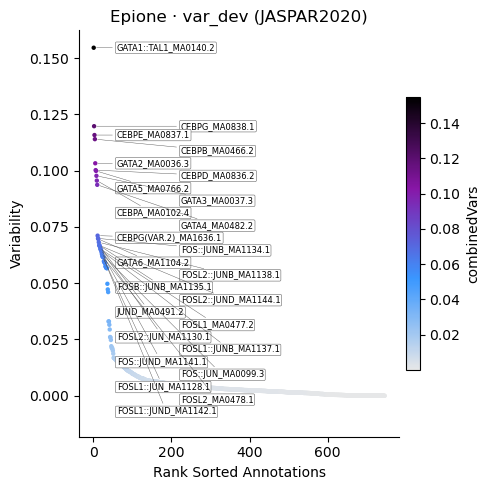

In [4]:
fig, ax = epi.pl.var_dev(adata, n=25, show=False)
ax.set_title('Epione · var_dev (JASPAR2020)')
plt.tight_layout(); plt.show()

The table and plot give the ranking for this dataset. With the default TF activity, the most variable motifs
are those of the GATA (erythroid / megakaryocyte) and CEBP (myeloid) families, followed by the AP-1 (FOS/JUN)
family. Lineage TFs such as SPI1 and EBF1 come out in the positive-regulator analysis below.

## 2 · Correlating gene scores with TF activity (`correlateMatrices`)

In [5]:
%%time
cor = epi.tl.correlate_matrices(
    adata, key2='tf_activity',
    name1='GeneScoreMatrix', name2='MotifMatrix',
    use_rep='X_iterative_lsi', scale_dims=True,      # ArchR IterativeLSI default scaleDims=TRUE
    depth_key='n_fragment', cor_cutoff=0.75,         # ArchR getReducedDims(corCutOff = 0.75)
    k=100, knn_iteration=500, overlap_cutoff=0.8, seed=1,
)
print(len(cor.attrs['groups']), 'kNN groups,', len(cor), 'gene–motif pairs')
cor.sort_values('cor', ascending=False).head(10)

   correlate_matrices: testing 685 mappings


   correlate_matrices: 500 non-overlapping kNN groups


500 kNN groups, 685 gene–motif pairs
CPU times: user 974 ms, sys: 212 ms, total: 1.19 s
Wall time: 1.07 s


,GeneScoreMatrix_name,MotifMatrix_name,cor,padj,pval,GeneScoreMatrix_matchName,MotifMatrix_matchName,GeneScoreMatrix_idx,MotifMatrix_idx
487,LEF1,LEF1_MA0768.1,0.909079,1.154127e-188,1.684856e-191,LEF1,LEF1,14580,227
503,TCF7,TCF7_MA0769.2,0.875589,1.195150e-156,1.744745e-159,TCF7,TCF7,15307,736
409,MAFB,MAFB_MA0117.2,0.856887,1.404162e-142,2.049872e-145,MAFB,MAFB,12095,156
669,GATA1,GATA1_MA0035.4,0.847933,1.555371e-136,2.270615e-139,GATA1,GATA1,19418,690
112,ETS1,ETS1_MA0098.3,0.838871,8.402600e-131,1.226657e-133,ETS1,ETS1,4127,232
414,CEBPB,CEBPB_MA0466.2,0.824138,3.339275e-122,4.874853e-125,CEBPB,CEBPB,12202,161
646,NFIL3,NFIL3_MA0025.2,0.784891,9.477618e-103,1.383594e-105,NFIL3,NFIL3,18731,713
54,ATF3,ATF3_MA0605.2,0.781179,4.015904e-101,5.862634e-104,ATF3,ATF3,1849,595
309,CEBPA,CEBPA_MA0102.4,0.752958,1.024590e-89,1.495752e-92,CEBPA,CEBPA,9717,670
511,EBF1,EBF1_MA0154.4,0.751277,4.373895e-89,6.385248e-92,EBF1,EBF1,15571,675


As in ArchR, LSI dimensions whose correlation with `log10(nFrags + 1)` exceeds `cor_cutoff = 0.75` are dropped
before the neighbour search (`depth_key` names the per-cell fragment count).

## 3 · Positive TF regulators

In [6]:
%%time
tf = epi.tl.positive_tf_regulators(
    adata, groupby='Clusters',                     # motif_key default: obsm['tf_activity']
    use_rep='X_iterative_lsi', scale_dims=True, depth_key='n_fragment', cor_cutoff=0.75,
    k=100, knn_iteration=500, seed=1,
)
tf[tf.TFRegulator == 'YES'][['GeneScoreMatrix_name', 'MotifMatrix_name', 'cor', 'padj', 'maxDelta']]

   correlate_matrices: testing 685 mappings


   correlate_matrices: 500 non-overlapping kNN groups


   positive_tf_regulators: 26 positive regulators: LEF1, TCF7, GATA1, ETS1, CEBPB, NFIL3, ATF3, CEBPA, EBF1, ETV6, GATA5, CEBPD, FOS, RUNX3, SPI1, EOMES, GATA2, TBX21, JDP2, MECOM
CPU times: user 763 ms, sys: 131 ms, total: 894 ms
Wall time: 823 ms


,GeneScoreMatrix_name,MotifMatrix_name,cor,padj,maxDelta
0,LEF1,LEF1_MA0768.1,0.909079,1.154127e-188,0.260762
1,TCF7,TCF7_MA0769.2,0.875589,1.195150e-156,0.321666
3,GATA1,GATA1_MA0035.4,0.847933,1.555371e-136,0.468602
4,ETS1,ETS1_MA0098.3,0.838871,8.402600e-131,0.140605
5,CEBPB,CEBPB_MA0466.2,0.824138,3.339275e-122,0.745528
6,NFIL3,NFIL3_MA0025.2,0.784891,9.477618e-103,0.388625
7,ATF3,ATF3_MA0605.2,0.781179,4.015904e-101,0.110744
9,CEBPA,CEBPA_MA0102.4,0.752958,1.024590e-89,0.708746
10,EBF1,EBF1_MA0154.4,0.751277,4.373895e-89,0.294828
14,ETV6,ETV6_MA0645.1,0.720859,1.740897e-78,0.136059


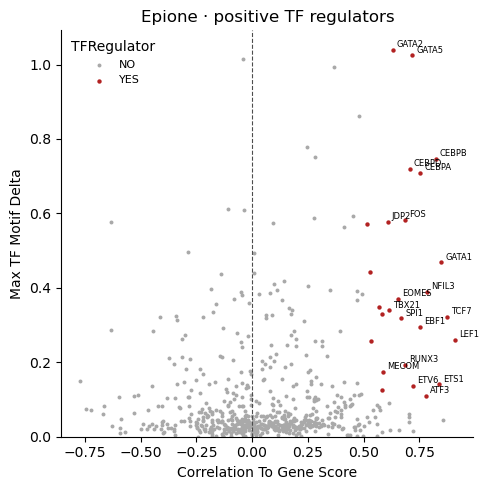

In [7]:
fig, ax = epi.pl.tf_regulators(adata, show=False)
ax.set_title('Epione · positive TF regulators')
plt.tight_layout(); plt.show()

## 4 · Parity vs ArchR 1.0.3

All three functions were compared with ArchR 1.0.3 (R 4.4.3) on the ArchR project of this dataset (10,660 cells,
3 samples), feeding both tools identical inputs: the IterativeLSI matrix, the GeneScoreMatrix, and the JASPAR2020
and cisbp chromVAR Z-scores exported from the same Arrow files. Gates were registered in
`tests/parity/var_dev_correlate/MANIFEST.md` before the first comparison and never loosened.

| Output | Class | Gate | Value |
|---|---|---|---|
| `combinedVars` (JASPAR2020 / cisbp) | 1 | ≤ 1e-8 | 2.8e-14 / 4.3e-14 |
| `combinedMeans` (JASPAR2020 / cisbp) | 1 | ≤ 1e-8 | 6.4e-16 / 7.1e-16 |
| variability rank | 1 | 0 mismatches | 0 |
| seed cells (`set.seed(1); sample()`) / kNN groups after overlap filter | 1 | exact | 0 of 500 / identical (492 groups) |
| `cor`, 825 gene–motif pairs | 1 | ≤ 1e-8 | 8.3e-16 |
| −log10 pval / −log10 padj | 1 bounded | ≤ 1e-6 | 3.8e-13 / 3.4e-13 |
| cluster means / `maxDelta` | 1 | ≤ 1e-8 | 1.8e-14 / 4.4e-14 |
| positive TF regulator set (39 TFs) | 7 | identical | identical, same row order |
| `rng="numpy"`: Spearman on `cor` / on −log10 padj | 8 | ≥ 0.90 | 0.989 / 0.954 |
| `rng="numpy"`: regulator-set Jaccard | 5 | ≥ 0.80 | 0.884 |

With the default `rng="archr"` Epione reproduces R's random stream bit-exactly, so it tests the same kNN groups as
ArchR; `rng="numpy"` is the only mode that is not 1:1, by design. The correlation and TF-regulator rows used the
cisbp motif set of the ArchR tutorial, whose names carry gene symbols.

The ArchR reference outputs are generated outside this repository. With them available, the comparison is rerun by
`tests/parity/var_dev_correlate/py_parity.py` and `tests/test_tf_regulators.py`, which read
`$EPIONE_ARCHR_PARITY_DIR/var_dev_correlate/` and are skipped otherwise.

### Notes
* `rng="archr"` (default) emulates `set.seed()` / `sample()` of a
  multi-threaded ArchR session bit-exactly, so Epione and ArchR test the
  *same* kNN groups. `rng="numpy"` gives a different
  but equally valid set of groups; the correlations then agree at the
  statistical level (Spearman ≥ 0.9) rather than to machine precision.
* The kNN search is exact Euclidean (ArchR uses `nabor::knn`), ties broken by
  cell index.
* Correlations need matching names: motif names map to genes after stripping
  `_…`/`-…` (cisbp `GATA1_383` → `GATA1`); JASPAR names (`MA0035.4_GATA1`) are
  renamed to TF-first form first, as in the setup above.